# 06 - Market regimes and distributional assumptions (Tests 4 and 5)

**Research questions.** (a) Do correlations, volatilities and optimiser behaviour differ across regimes? (b) Are Gaussian assumptions defensible?

**Labelling caution.** *Ex-post* labels use the full sample and are for **description** only. *Ex-ante* labels use only past data. Never use ex-post labels to drive a trading rule. Stress windows are conventional episodes whose boundaries are judgement calls - adjust and justify them.

In [1]:
import sys, warnings
import os
from pathlib import Path
try:  
    os.chdir(Path(__vsc_ipynb_file__).resolve().parent)
except NameError:  
    pass
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import data_processing as dp, covariance_estimators as ce, portfolio_models as pm
from src import stability_tests as st, regime_detection as rd, stress_testing as sx, evaluation as ev
from src.backtesting import walk_forward, make_models, in_sample_vs_out_of_sample
plt.rcParams["figure.dpi"] = 110
_candidates = ["returns_simple_daily.csv"]
_path = next((Path("../data/processed") / f for f in _candidates if (Path("../data/processed") / f).exists()), None)
if _path is None:
    raise FileNotFoundError("Run notebook 01 first: expected ../data/processed/returns_simple_daily.csv")
returns = pd.read_csv(_path, index_col=0, parse_dates=True)
print("loaded:", _path.name)
X = returns.to_numpy()
WINDOW = 504
print(returns.shape, returns.index[0].date(), "->", returns.index[-1].date())

loaded: returns_simple_daily.csv
(3519, 5) 2012-01-04 -> 2025-12-31


## 1. Regime labels

vol_ex_post {'mid_vol': 0.34, 'low_vol': 0.33, 'high_vol': 0.33}
vol_ex_ante {'high_vol': 0.387, 'low_vol': 0.312, 'mid_vol': 0.3}
bull_bear {'bull': 0.925, 'bear': 0.075}
stress {'normal': 0.908, 'stress': 0.092}


,regime,label,share
0,vol_ex_post,mid_vol,0.340
1,vol_ex_post,low_vol,0.330
2,vol_ex_post,high_vol,0.330
3,vol_ex_ante,high_vol,0.387
4,vol_ex_ante,low_vol,0.312
5,vol_ex_ante,mid_vol,0.300
6,bull_bear,bull,0.925
7,bull_bear,bear,0.075
8,stress,normal,0.908
9,stress,stress,0.092


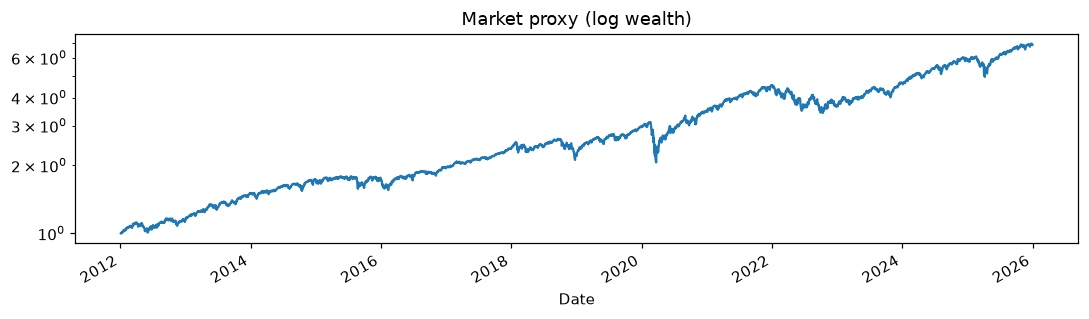

In [2]:
mkt = rd.market_proxy(returns, "SPY" if "SPY" in returns else None)
reg = pd.DataFrame({
    "vol_ex_post": rd.volatility_regimes_ex_post(mkt),
    "vol_ex_ante": rd.volatility_regimes_ex_ante(mkt),
    "bull_bear": rd.bull_bear_regimes(mkt),
    "stress": rd.stress_labels(returns.index),
})
for c in reg: print(c, reg[c].value_counts(normalize=True).round(3).to_dict())
ax = (1 + mkt).cumprod().plot(logy=True, figsize=(10, 3), title="Market proxy (log wealth)")
fig = ax.get_figure()
plt.tight_layout()
from pathlib import Path
figure_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\market_proxy_log_wealth.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
table_dir = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables")
table_dir.mkdir(parents=True, exist_ok=True)
reg.to_csv(table_dir / "market_regime_labels.csv", index_label="date")
regime_shares = pd.concat(
    [reg[c].value_counts(normalize=True).rename("share").rename_axis("label").reset_index().assign(regime=c)
     for c in reg],
    ignore_index=True,
)[["regime", "label", "share"]].round(3)
regime_shares.to_csv(table_dir / "market_regime_shares.csv", index=False)
regime_shares

**Interpret:** how often do the ex-post and ex-ante volatility labels disagree? What does that disagreement tell you about the *usability* of regime knowledge?

In [3]:
print(pd.crosstab(reg["vol_ex_post"], reg["vol_ex_ante"], normalize="index").round(2))

vol_ex_ante  high_vol  low_vol  mid_vol
vol_ex_post                            
high_vol         0.99     0.00     0.01
low_vol          0.00     0.91     0.09
mid_vol          0.16     0.02     0.82


## 2. Do correlations and covariances differ by regime?

In [4]:
def mean_corr(df):
    C = df.corr().values; n = len(C); return (C.sum() - n) / (n * (n - 1))
tab = {}
for scheme in ["vol_ex_post", "bull_bear", "stress"]:
    for lab, idx in reg[scheme].dropna().groupby(reg[scheme].dropna()).groups.items():
        sub = returns.loc[idx]
        if len(sub) > 60:
            tab[(scheme, lab)] = {"n_obs": len(sub), "mean_corr": mean_corr(sub),
                                  "avg_ann_vol": float(sub.std().mean() * np.sqrt(252)),
                                  "cond_number": ce.condition_number(ce.sample_covariance(sub.values))}
regime_summary = pd.DataFrame(tab).T.round(3)
from pathlib import Path
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\market_regime_covariance_diagnostics.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
regime_summary.to_csv(table_path, index_label=["scheme", "regime"])
regime_summary

n_obs  mean_corr  avg_ann_vol  cond_number
vol_ex_post high_vol  1155.0      0.357        0.197       47.441
            low_vol   1155.0      0.254        0.097       28.630
            mid_vol   1189.0      0.295        0.121       32.760
bull_bear   bear       263.0      0.516        0.253       53.225
            bull      3256.0      0.276        0.132       45.503
stress      normal    3195.0      0.288        0.127       38.900
            stress     324.0      0.422        0.259       50.496

In [5]:
hi = returns[reg["vol_ex_post"] == "high_vol"].values; lo_ = returns[reg["vol_ex_post"] == "low_vol"].values
box_m_results = {k: round(v, 4) for k, v in st.box_m_test(hi, lo_).items()}
frobenius_change = round(st.frobenius_change(ce.sample_covariance(lo_), ce.sample_covariance(hi)), 3)
gmv_turnover = round(0.5 * np.abs(pm.gmv_long_only(lo_) - pm.gmv_long_only(hi)).sum(), 3)
print("Box's M, high vs low vol:", box_m_results)
print("relative Frobenius change:", frobenius_change)
print("GMV weight turnover-equivalent (low-vol fit vs high-vol fit):", gmv_turnover)
vol_comparison = pd.Series({
    **{f"box_m_{k}": v for k, v in box_m_results.items()},
    "relative_frobenius_change": frobenius_change,
    "gmv_turnover_equivalent": gmv_turnover,
}, name="value").to_frame()
from pathlib import Path
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\high_low_volatility_comparison.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
vol_comparison.to_csv(table_path)
vol_comparison

Box's M, high vs low vol: {'statistic': 2134.8116, 'dof': 15.0, 'p_value': 0.0}
relative Frobenius change: 4.604
GMV weight turnover-equivalent (low-vol fit vs high-vol fit): 0.121


,value
box_m_statistic,2134.8116
box_m_dof,15.0000
box_m_p_value,0.0000
relative_frobenius_change,4.6040
gmv_turnover_equivalent,0.1210


**Interpret:** by how much does the *optimal portfolio* change when the covariance is estimated in calm vs turbulent periods? Is that an argument for or against conditional-volatility models?

## 3. Tail dependence

In [6]:
cols = list(returns.columns)
a, b = cols[0], cols[min(1, len(cols) - 1)]
pairs = [(a, b)] + ([("SPY", "TLT")] if {"SPY", "TLT"} <= set(cols) else []) + ([("SPY", "EEM")] if {"SPY", "EEM"} <= set(cols) else [])
rows = {}
for x, y in pairs:
    r = np.corrcoef(returns[x], returns[y])[0, 1]
    td = st.tail_dependence_empirical(returns[x], returns[y], 0.05)
    rows[f"{x}-{y}"] = {"corr": r, **td}
tail_dependence_summary = pd.DataFrame(rows).T.round(3)
from pathlib import Path
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\tail_dependence_pairwise_summary.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
tail_dependence_summary.to_csv(table_path, index_label="asset_pair")
tail_dependence_summary

,corr,lower_tail,upper_tail
SPY-EFA,0.846,0.58,0.562


**Interpret:** for a bivariate Gaussian with this correlation, what lower-tail co-exceedance probability would you expect at the 5% level? (Compute it by simulation: draw 1e6 bivariate normals with the correlation above.) Compare.

## 4. Distributional assumption tests

In [7]:
norm = st.univariate_normality_table(returns)
norm[["skew", "excess_kurtosis", "JB_pvalue", "n_beyond_4sd"]].round(4)

,skew,excess_kurtosis,JB_pvalue,n_beyond_4sd
SPY,-0.3188,14.6941,0.0,25.0
EFA,-0.7342,12.2022,0.0,17.0
AGG,-1.0579,20.8755,0.0,16.0
GLD,-0.4061,4.9546,0.0,16.0
VNQ,-1.0459,20.5720,0.0,22.0


In [8]:
mardia_results = {k: round(v, 4) for k, v in st.mardia_test(returns).items()}
arch_results = pd.DataFrame({c: st.arch_lm_test(returns[c], 5) for c in returns.columns}).T.round(4)
print("Mardia:", mardia_results)
print()
print(arch_results)
from pathlib import Path
table_dir = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables")
table_dir.mkdir(parents=True, exist_ok=True)
pd.Series(mardia_results, name="value").to_frame().to_csv(table_dir / "mardia_test_results.csv", index_label="statistic")
arch_results.to_csv(table_dir / "arch_lm_test_by_asset.csv", index_label="asset")

Mardia: {'mardia_skewness': 6.2803, 'skew_stat': 3683.414, 'skew_p': 0.0, 'mardia_kurtosis': 145.2231, 'kurt_expected_under_normal': 35.0, 'kurt_z': 390.7538, 'kurt_p': 0.0}

            LM  p_value  lags
SPY   968.5485      0.0   5.0
EFA   823.1581      0.0   5.0
AGG  1162.0914      0.0   5.0
GLD   114.3196      0.0   5.0
VNQ  1057.2501      0.0   5.0


**Interpret:**
1. How many 4-sigma days would a Gaussian produce in `T` observations? Compare with `n_beyond_4sd`.
2. ARCH-LM rejects for which assets? What does volatility clustering imply for the *unconditional* sample covariance used by most models?
3. Statistical rejection of normality is nearly guaranteed at this sample size. Argue what matters instead: *economic* consequence for the portfolio (e.g. do tails change the minimum-variance weights?).

## 5. Stationarity

In [9]:
try:
    prices = pd.read_csv("../data/processed/prices_adjusted_aligned.csv", index_col=0, parse_dates=True)[returns.columns]
except FileNotFoundError as e:
    print("ADF table skipped; input prices file not found:", e)
else:
    adf_results = st.adf_table(returns, prices).round(4)
    display(adf_results)
    from pathlib import Path
    table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\adf_stationarity_tests.csv")
    table_path.parent.mkdir(parents=True, exist_ok=True)
    adf_results.to_csv(table_path)

,ADF_returns_stat,ADF_returns_p,ADF_logprice_stat,ADF_logprice_p
SPY,-13.3048,0.0,-0.2296,0.9349
EFA,-19.9634,0.0,-0.9436,0.7733
AGG,-11.7290,0.0,-1.1713,0.6858
GLD,-59.8082,0.0,1.7461,0.9982
VNQ,-19.0139,0.0,-1.9362,0.3152


**Interpret:** returns are stationary in the ADF sense but their *variance* clearly is not. State precisely why ADF stationarity does not guarantee a stable covariance matrix.

## Interpretation

The results show that **risk and correlations vary across market conditions**, and that return distributions depart substantially from the Gaussian assumptions often used in portfolio models.

### Regimes and covariance

Ex-post volatility labels divide the sample into roughly equal low-, medium-, and high-volatility periods. Ex-post and ex-ante labels agree about **84%** of the time, but they sometimes differ—especially for medium-volatility periods. Ex-post labels use future data, so they are descriptive only; ex-ante labels are more appropriate for decisions made in real time.

Correlations rise in turbulent periods: mean pairwise correlation is **0.254** in low-volatility periods and **0.357** in high-volatility periods. It is also higher in bear markets (**0.516**, versus **0.276** in bull markets) and designated stress periods (**0.422**, versus **0.288** in normal periods).

The high- versus low-volatility covariance comparison shows a large difference (relative Frobenius change **4.604**). Re-estimating GMV weights across those periods shifts about **12% of the portfolio** on a one-way turnover-equivalent basis. This supports considering conditional covariance models, but does not show by itself that they improve out-of-sample results.

### Tail behavior and distributional assumptions

For SPY and EFA, the observed lower-tail co-exceedance is **0.58**. A Gaussian simulation using their observed correlation gives about **0.55**. The observed value is somewhat higher, but close; this pair does not show a large excess beyond what its high overall correlation already implies.

All five assets have strongly negative Jarque–Bera p-values (reported as **0.0000**), negative skew, and excess kurtosis. Each has **16–25** days beyond four standard deviations, compared with about **0.2** expected per asset under a Gaussian distribution. Mardia’s test also rejects multivariate normality. These results point to heavy tails and downside asymmetry.

ARCH-LM tests reject the absence of volatility clustering for every asset. This means risk changes over time, so a single unconditional covariance estimate can average together calmer and more turbulent periods.

### Stationarity

The ADF tests reject a unit root for returns, but do not reject one for log prices. This does **not** imply a stable covariance matrix: ADF tests for unit-root behavior in each series, not whether variances and cross-asset covariances remain constant. The regime and ARCH results show why those are separate questions.

**Overall:** the evidence suggests regime-dependent covariance, volatility clustering, and non-Gaussian tails. Risk estimates and portfolio weights can change across regimes, so evaluate conditional models out of sample before concluding they are better.

